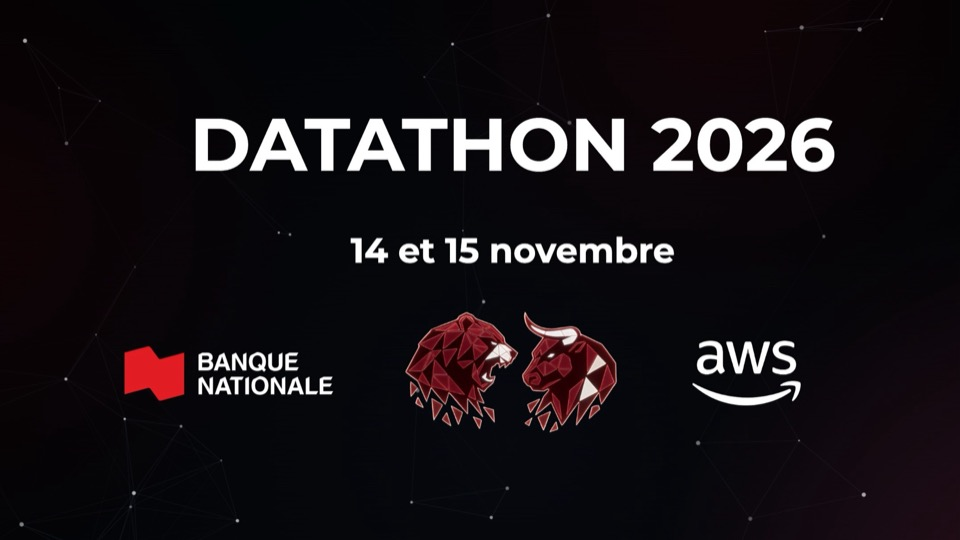

# Bienvenue dans l'aventure !

Prépare-toi à vivre **un week-end intense de collaboration, d'analyse et d'innovation** où se rencontrent **finance, science des données et intelligence artificielle.**

Le Datathon PolyFinances 2026, c'est bien plus qu'une compétition : c'est **une immersion dans la réalité de la finance,** où tes idées et ton esprit analytique feront la différence.

## Rappel du défi : AlphaForge AI

**Contexte :** Les investisseurs disposent d'une abondance d'informations (cours de marché, publications d'entreprises, conditions macroéconomiques, nouvelles financières, indicateurs de risque). La difficulté consiste à les sélectionner, les mettre en relation et en tirer des conclusions compréhensibles selon le contexte de chaque investisseur.

**Objectif :** Concevoir une solution originale utilisant l'intelligence artificielle et des **données financières publiques** pour appuyer l'analyse ou la prise de décision en investissement, en tenant compte de différents profils d'investisseurs et en choisissant librement les actifs pertinents.

**Personas de référence :**

| Persona | Risque | Objectif indicatif |
|---------|--------|--------------------|
| Prudent | Faible | Préserver le capital, rechercher la stabilité, maîtriser la volatilité et la concentration |
| Équilibré | Modéré | Concilier croissance et stabilité, diversifier, arbitrer entre potentiel et risque |
| Audacieux | Élevé | Rechercher un potentiel de croissance plus important, accepter davantage de fluctuations |

**À retenir :** L'objectif n'est pas de trouver le portefeuille au meilleur rendement passé, mais de démontrer une démarche crédible, innovante et utile. Le défi se déroule **uniquement en simulation** : aucune transaction réelle et aucun conseil financier personnalisé.

**Il est fortement recommandé de lire attentivement l'énoncé complet du défi partagé avec tous les participants pour comprendre tous les détails, livrables et critères d'appréciation.**

---

## Votre environnement

Ce notebook fonctionne dans JupyterLab sur AWS (par exemple dans Amazon SageMaker Unified Studio) ou sur votre ordinateur avec les identifiants de votre compte AWS du Datathon. Utilisez la région `us-east-1`.

**Important :** L'utilisation de cet environnement n'est pas obligatoire. Vous disposez de droits d'administration sur votre compte AWS et êtes libres d'utiliser les services et outils de votre choix pour développer votre solution.

**Attention :** Les comptes AWS seront fermés et toutes les données détruites le **lundi 16 novembre à 13 h 59**. Téléchargez vos notebooks, votre code et vos résultats avant cette date.

### Installation des bibliothèques

Si pip affiche un avertissement sur `sagemaker-studio` et des paquets `pymongo` manquants, il vient de l'image SageMaker et n'empêche pas ce notebook de fonctionner.

In [1]:
%pip install --quiet yfinance strands-agents

Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import os

import boto3
import numpy as np
import pandas as pd
import requests
import yfinance as yf
from IPython.display import Markdown, display

# Région AWS de votre environnement
REGION = boto3.session.Session().region_name or "us-east-1"
print(f"Région AWS : {REGION}")

# Dossier local pour conserver les données téléchargées (traçabilité)
DOSSIER_DONNEES = "donnees"
os.makedirs(DOSSIER_DONNEES, exist_ok=True)

Région AWS : us-east-1


---

## Les données publiques

Aucun jeu de données n'est imposé : vous choisissez les actifs et les sources pertinents pour votre approche. Les exemples ci-dessous utilisent des sources publiques citées dans l'énoncé. Pour chaque source, notez la date, la devise et les traitements appliqués, et respectez ses conditions d'utilisation.

| Source | Données | Accès |
|--------|---------|-------|
| Yahoo Finance (bibliothèque `yfinance`) | Prix quotidiens, dividendes, fractionnements | Sans clé, usage personnel et éducatif |
| [Banque du Canada (Valet)](https://www.banqueducanada.ca/valet/docs) | Taux de change, taux directeur | Sans clé |
| [FRED](https://fred.stlouisfed.org/) | Séries macroéconomiques et taux américains | Sans clé pour le téléchargement CSV |
| [SEC EDGAR](https://www.sec.gov/search-filings/edgar-application-programming-interfaces) | Données financières déclarées par les entreprises américaines | Sans clé, en-tête `User-Agent` avec un courriel obligatoire |

### Prix quotidiens d'un échantillon d'actifs

Les symboles ci-dessous sont des exemples indicatifs tirés de l'énoncé. Modifiez la liste librement.

In [3]:
ACTIFS = {
    "RY.TO": "Banque Royale (actions canadiennes)",
    "SHOP.TO": "Shopify (actions canadiennes)",
    "AAPL": "Apple (actions américaines)",
    "MSFT": "Microsoft (actions américaines)",
    "XIU.TO": "FNB S&P/TSX 60",
    "SPY": "FNB S&P 500",
    "XBB.TO": "FNB obligataire canadien",
    "AGG": "FNB obligataire américain",
    "GLD": "FNB lié à l'or",
    "BTC-USD": "Bitcoin",
}

prix = yf.download(list(ACTIFS), period="5y", interval="1d", auto_adjust=True, progress=False)["Close"]
prix = prix[list(ACTIFS)]
prix.to_csv(f"{DOSSIER_DONNEES}/prix_quotidiens.csv")

print(f"{prix.shape[0]} jours, de {prix.index.min():%Y-%m-%d} à {prix.index.max():%Y-%m-%d}")
prix.dropna(thresh=len(ACTIFS) // 2).tail()

1827 jours, de 2021-11-14 à 2026-11-14


Ticker,RY.TO,SHOP.TO,AAPL,MSFT,XIU.TO,SPY,XBB.TO,AGG,GLD,BTC-USD
Date,,,,,,,,,,
2026-11-09,288.320007,214.860001,350.423737,545.179993,54.669998,752.690002,27.799999,96.580002,379.529999,75223.148438
2026-11-10,287.559998,208.119995,348.245392,533.159973,54.349998,749.919983,27.670000,95.879997,369.359985,73720.117188
2026-11-11,290.000000,212.570007,355.359985,521.130005,54.820000,759.809998,27.660000,95.839996,365.170013,73964.468750
2026-11-12,289.390015,209.410004,354.880005,523.000000,54.549999,757.119995,27.530001,95.220001,354.890015,71342.968750
2026-11-13,288.369995,209.740005,356.269989,523.880005,54.549999,754.369995,27.430000,95.089996,355.450012,68249.273438


### Taux de change CAD/USD (Banque du Canada)

Les actifs sont cotés en CAD ou en USD. Pour les comparer, convertissez-les dans une même devise.

In [4]:
reponse = requests.get("https://www.bankofcanada.ca/valet/observations/FXUSDCAD/json?start_date=2021-01-01", timeout=30)
reponse.raise_for_status()

usd_cad = pd.Series(
    {obs["d"]: float(obs["FXUSDCAD"]["v"]) for obs in reponse.json()["observations"]},
    name="USD_CAD",
)
usd_cad.index = pd.to_datetime(usd_cad.index)
usd_cad.to_csv(f"{DOSSIER_DONNEES}/taux_change_usd_cad.csv")

print(f"1 USD = {usd_cad.iloc[-1]:.4f} CAD au {usd_cad.index[-1]:%Y-%m-%d}")

1 USD = 1.4257 CAD au 2026-11-13


### Données macroéconomiques (FRED)

Exemple : le taux des obligations du Trésor américain à 10 ans (`DGS10`). Explorez le [catalogue FRED](https://fred.stlouisfed.org/) pour d'autres séries (inflation, chômage, etc.).

In [5]:
reponse = requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10", timeout=30)
reponse.raise_for_status()

taux_10_ans = pd.read_csv(io.StringIO(reponse.text), index_col=0, parse_dates=True, na_values=".")["DGS10"].dropna()
taux_10_ans.to_csv(f"{DOSSIER_DONNEES}/fred_dgs10.csv")

print(f"Taux du Trésor américain à 10 ans : {taux_10_ans.iloc[-1]:.2f} % au {taux_10_ans.index[-1]:%Y-%m-%d}")

Taux du Trésor américain à 10 ans : 5.10 % au 2026-11-12


### Données financières d'entreprises (SEC EDGAR)

L'API de la SEC exige un en-tête `User-Agent` qui vous identifie. Remplacez le courriel par le vôtre.

In [6]:
ENTETES_SEC = {"User-Agent": "Equipe Datathon PolyFinances votre.courriel@exemple.com"}

# Apple : CIK 0000320193. Trouvez le CIK d'une entreprise sur https://www.sec.gov/search-filings
reponse = requests.get("https://data.sec.gov/api/xbrl/companyfacts/CIK0000320193.json", headers=ENTETES_SEC, timeout=30)
reponse.raise_for_status()
faits = reponse.json()["facts"]["us-gaap"]

revenus = pd.DataFrame(faits["RevenueFromContractWithCustomerExcludingAssessedTax"]["units"]["USD"])
duree_jours = (pd.to_datetime(revenus["end"]) - pd.to_datetime(revenus["start"])).dt.days
revenus_annuels = revenus[(revenus["form"] == "10-K") & duree_jours.between(350, 380)].drop_duplicates("end").tail(5)
revenus_annuels[["end", "val", "filed"]].rename(columns={"end": "fin_exercice", "val": "revenus_usd", "filed": "date_depot"})

,fin_exercice,revenus_usd,date_depot
73,2022-09-24,394328000000,2022-10-28
86,2023-09-30,383285000000,2023-11-03
99,2024-09-28,391035000000,2024-11-01
112,2025-09-27,416161000000,2025-10-31
119,2026-09-26,478834000000,2026-11-03


---

## Indicateurs de risque et de rendement

Quelques indicateurs simples, calculés sur les rendements quotidiens. Ils ne présument pas des rendements futurs.

In [7]:
# Rendements calculés actif par actif : les actions ne se négocient pas la fin de semaine, contrairement aux cryptoactifs
rendements = prix.apply(lambda serie: serie.dropna().pct_change())
# 252 jours de bourse par an (365 pour les cryptoactifs, qui se négocient tous les jours)
jours_par_an = pd.Series({s: 365 if s.endswith("-USD") else 252 for s in prix.columns})


def perte_maximale(serie):
    serie = serie.dropna()
    return (serie / serie.cummax() - 1).min()


indicateurs = pd.DataFrame({
    "description": pd.Series(ACTIFS),
    "rendement_annualise": (1 + rendements.mean()) ** jours_par_an - 1,
    "volatilite_annualisee": rendements.std() * np.sqrt(jours_par_an),
    "perte_maximale": prix.apply(perte_maximale),
})
indicateurs["ratio_rendement_risque"] = indicateurs["rendement_annualise"] / indicateurs["volatilite_annualisee"]
indicateurs = indicateurs.sort_values("volatilite_annualisee")

# Affichage en pourcentages (les valeurs de `indicateurs` restent numériques)
affichage = indicateurs.copy()
for colonne in ["rendement_annualise", "volatilite_annualisee", "perte_maximale"]:
    affichage[colonne] = affichage[colonne].map("{:.1%}".format)
affichage["ratio_rendement_risque"] = affichage["ratio_rendement_risque"].map("{:.2f}".format)
affichage

,description,rendement_annualise,volatilite_annualisee,perte_maximale,ratio_rendement_risque
AGG,FNB obligataire américain,-0.1%,6.2%,-17.2%,-0.01
XBB.TO,FNB obligataire canadien,0.9%,6.6%,-15.5%,0.14
XIU.TO,FNB S&P/TSX 60,14.8%,13.1%,-16.4%,1.13
RY.TO,Banque Royale (actions canadiennes),22.6%,15.5%,-21.2%,1.46
SPY,FNB S&P 500,13.3%,17.3%,-24.5%,0.77
GLD,FNB lié à l'or,17.6%,19.2%,-28.4%,0.91
AAPL,Apple (actions américaines),24.4%,28.2%,-33.4%,0.87
MSFT,Microsoft (actions américaines),14.8%,28.5%,-37.1%,0.52
BTC-USD,Bitcoin,13.8%,50.8%,-75.9%,0.27
SHOP.TO,Shopify (actions canadiennes),23.2%,64.4%,-83.5%,0.36


In [8]:
# Corrélations entre les actifs : utiles pour juger de la diversification
rendements.corr().round(2)

Ticker,RY.TO,SHOP.TO,AAPL,MSFT,XIU.TO,SPY,XBB.TO,AGG,GLD,BTC-USD
Ticker,,,,,,,,,,
RY.TO,1.00,0.32,0.34,0.27,0.73,0.54,0.13,0.14,0.09,0.22
SHOP.TO,0.32,1.00,0.44,0.44,0.54,0.57,0.15,0.15,0.05,0.33
AAPL,0.34,0.44,1.00,0.53,0.50,0.71,0.13,0.16,0.06,0.27
MSFT,0.27,0.44,0.53,1.00,0.43,0.69,0.07,0.12,0.09,0.34
XIU.TO,0.73,0.54,0.50,0.43,1.00,0.77,0.19,0.22,0.33,0.36
SPY,0.54,0.57,0.71,0.69,0.77,1.00,0.15,0.22,0.16,0.43
XBB.TO,0.13,0.15,0.13,0.07,0.19,0.15,1.00,0.82,0.24,0.04
AGG,0.14,0.15,0.16,0.12,0.22,0.22,0.82,1.00,0.30,0.09
GLD,0.09,0.05,0.06,0.09,0.33,0.16,0.24,0.30,1.00,0.16


---

## L'IA générative avec Amazon Bedrock

Exemple d'utilisation simple avec l'API Converse. Les modèles les plus récents sont accessibles via un profil d'inférence global (préfixe `global.`). Tous les modèles disponibles dans Amazon Bedrock sont permis pendant le Datathon.

In [9]:
# Modèles utilisés dans ce notebook. Consultez la liste plus bas pour en choisir d'autres.
# Claude Sonnet 5.5 et Haiku 5.5 ne sont pas disponibles dans les comptes du Datathon.
MODELE_PRINCIPAL = "global.anthropic.claude-sonnet-5"
MODELE_RAPIDE = "global.anthropic.claude-haiku-4-5-20251001-v1:0"

bedrock_runtime = boto3.client("bedrock-runtime", region_name=REGION)


def texte_reponse(reponse):
    # Retourne le texte d'une réponse Converse (certains modèles ajoutent d'abord un bloc de raisonnement)
    return "".join(bloc["text"] for bloc in reponse["output"]["message"]["content"] if "text" in bloc)


reponse = bedrock_runtime.converse(
    modelId=MODELE_RAPIDE,
    messages=[{"role": "user", "content": [{"text": "Explique en 3 phrases ce qu'est la volatilité d'un actif financier."}]}],
)

display(Markdown(texte_reponse(reponse)))

# La Volatilité d'un Actif Financier

La volatilité mesure l'ampleur et la fréquence des fluctuations du prix d'un actif financier sur une période donnée. Elle quantifie le risque associé à cet actif : plus la volatilité est élevée, plus les variations de prix sont importantes et imprévisibles. Une volatilité faible indique un actif stable, tandis qu'une volatilité forte caractérise un actif plus risqué mais potentiellement plus rentable.

### Adapter l'explication au profil de l'investisseur

La même information financière peut être interprétée différemment selon le persona. Ici, le modèle reçoit les indicateurs calculés plus haut et un profil fictif.

In [10]:
CONSIGNES_SYSTEME = (
    "Tu es un analyste qui aide des étudiants dans un concours de finance simulée. "
    "Base-toi uniquement sur les données fournies, distingue les faits des hypothèses et signale les limites. "
    "Il s'agit d'une simulation : ne présente jamais ta réponse comme un conseil financier personnalisé."
)

persona = "Prudent : risque faible, préserver le capital, rechercher la stabilité, maîtriser la volatilité et la concentration."

reponse = bedrock_runtime.converse(
    modelId=MODELE_PRINCIPAL,
    system=[{"text": CONSIGNES_SYSTEME}],
    messages=[{
        "role": "user",
        "content": [{"text": (
            f"Profil fictif : {persona}\n\n"
            f"Indicateurs historiques sur 5 ans :\n{indicateurs.round(3).to_string()}\n\n"
            "En 150 mots maximum, quels actifs semblent cohérents avec ce profil, lesquels ne le sont pas, et pourquoi ?"
        )}],
    }],
)

display(Markdown(texte_reponse(reponse)))

# Analyse pour un profil Prudent

**Cohérents avec le profil :**
- **XBB.TO** (obligataire canadien) : volatilité la plus faible (6,6%), perte max limitée (-15,5%), rendement modeste mais positif. C'est l'actif le plus aligné sur la préservation du capital.
- **AGG** (obligataire américain) : volatilité comparable (6,2%), mais rendement légèrement négatif sur la période — stabilité sans compensation de rendement.

**Discutables, à surveiller :**
- **XIU.TO** (TSX 60) : volatilité plus élevée (13,1%) mais ratio rendement/risque solide (1,132). Pourrait être une petite exposition actions si le profil tolère un minimum de risque.

**Incohérents avec le profil :**
- **SHOP.TO, BTC-USD, AAPL, MSFT, GLD, SPY, RY.TO** : volatilités élevées (15,5% à 64,4%) et pertes maximales sévères (-21% à -83,5%), incompatibles avec la maîtrise de la volatilité recherchée.

**Limite importante** : ces données historiques sur 5 ans ne garantissent pas les performances futures ; elles ne remplacent pas une analyse de corrélation entre actifs ni un contexte macroéconomique actuel. Ceci est une analyse pédagogique, non un conseil personnalisé.

### Liste des modèles disponibles

In [11]:
from botocore.exceptions import ClientError

bedrock = boto3.client("bedrock", region_name=REGION)

try:
    profils = []
    for page in bedrock.get_paginator("list_inference_profiles").paginate(typeEquals="SYSTEM_DEFINED"):
        profils.extend(page["inferenceProfileSummaries"])
    for profil in sorted(profils, key=lambda p: p["inferenceProfileId"]):
        if profil["inferenceProfileId"].startswith("global."):
            print(profil["inferenceProfileId"])
except ClientError as erreur:
    if erreur.response["Error"]["Code"] != "AccessDeniedException":
        raise
    print("Le rôle de ce notebook n'a pas le droit de lister les modèles (bedrock:ListInferenceProfiles).")
    print("Ajoutez la politique AmazonBedrockFullAccess au rôle AmazonSageMaker-ExecutionRole-... :")
    print("voir la page « SageMaker Unified Studio et notebook d'introduction » de l'atelier.")
    print("Les appels de modèles plus haut fonctionnent sans cette permission.")

global.amazon.nova-2-lite-v1:0
global.anthropic.claude-fable-5
global.anthropic.claude-fable-5-1
global.anthropic.claude-fable-5-2
global.anthropic.claude-haiku-4-5-20251001-v1:0
global.anthropic.claude-haiku-5-5
global.anthropic.claude-opus-4-5-20251101-v1:0
global.anthropic.claude-opus-4-6-v1
global.anthropic.claude-opus-4-7
global.anthropic.claude-opus-4-8
global.anthropic.claude-opus-5
global.anthropic.claude-opus-5-5
global.anthropic.claude-sonnet-4-5-20250929-v1:0
global.anthropic.claude-sonnet-4-6
global.anthropic.claude-sonnet-5
global.anthropic.claude-sonnet-5-5
global.cohere.embed-v4:0
global.moonshotai.kimi-k3
global.moonshotai.kimi-k3.1
global.openai.gpt-5.4
global.openai.gpt-5.5
global.openai.gpt-5.6-luna
global.openai.gpt-5.6-sol
global.openai.gpt-5.6-terra
global.openai.gpt-6-astra
global.openai.gpt-6-luna
global.openai.gpt-6-sol
global.openai.gpt-6.1-sol
global.openai.gpt-6.1-terra
global.twelvelabs.pegasus-1-2-v1:0
global.twelvelabs.pegasus-1-5-v1:0
global.xai.grok-4.6

---

## Extraire des données structurées d'un texte

Les nouvelles et communiqués sont des données qualitatives. Avec les **sorties structurées** d'Amazon Bedrock, vous donnez un schéma JSON au modèle et sa réponse respecte ce schéma. Ici, le schéma vient d'une classe [Pydantic](https://docs.pydantic.dev/), qui sert aussi à valider la réponse avant de la combiner avec vos données quantitatives.

In [12]:
import json
from typing import Literal

from pydantic import BaseModel, ConfigDict, Field


class SignalNouvelle(BaseModel):
    model_config = ConfigDict(extra="forbid")  # exigé par Bedrock : additionalProperties = false

    entreprise: str
    symbole_boursier: str
    type_evenement: Literal["résultats", "acquisition", "réglementation", "direction", "autre"]
    sentiment: Literal["positif", "neutre", "négatif"]
    chiffres_cles: list[str] = Field(description="Chiffres mentionnés, avec leur unité")
    risques_mentionnes: list[str]


# Communiqué fictif
texte = (
    "Exemple Corp. (NASDAQ: EXMP) a annoncé aujourd'hui ses résultats du troisième trimestre 2026. "
    "Les revenus ont atteint 4,2 milliards de dollars américains, en hausse de 12 % sur un an, et le bénéfice "
    "par action s'établit à 1,87 $. La direction souligne toutefois l'incertitude liée aux nouveaux tarifs "
    "douaniers, la volatilité des taux de change et un ralentissement de la demande en Europe."
)

reponse = bedrock_runtime.converse(
    modelId=MODELE_RAPIDE,
    messages=[{"role": "user", "content": [{"text": f"Analyse ce communiqué : {texte}"}]}],
    inferenceConfig={"maxTokens": 1000},
    outputConfig={"textFormat": {"type": "json_schema", "structure": {"jsonSchema": {
        "name": "signal_nouvelle",
        "description": "Signaux extraits d'un communiqué financier",
        "schema": json.dumps(SignalNouvelle.model_json_schema()),  # une chaîne JSON, pas un dictionnaire
    }}}},
)

signal = SignalNouvelle.model_validate_json(texte_reponse(reponse))
signal.model_dump()

{'entreprise': 'Exemple Corp.',
 'symbole_boursier': 'EXMP',
 'type_evenement': 'résultats',
 'sentiment': 'neutre',
 'chiffres_cles': ['4,2 milliards de dollars américains',
  '12% de hausse sur un an',
  '1,87$ de bénéfice par action'],
 'risques_mentionnes': ['incertitude liée aux nouveaux tarifs douaniers',
  'volatilité des taux de change',
  'ralentissement de la demande en Europe']}

---

## Un agent qui utilise vos données

Un agent combine un modèle et des **outils** : des fonctions Python qu'il peut décider d'appeler. Voici un exemple simple avec [Strands Agents](https://strandsagents.com/), où l'agent consulte les indicateurs calculés plus haut au lieu de les inventer.

In [13]:
from strands import Agent, tool
from strands.models import BedrockModel


@tool
def indicateurs_actif(symbole: str) -> dict:
    """Retourne les indicateurs historiques (rendement, volatilité, perte maximale) d'un actif de l'échantillon.

    Args:
        symbole: Symbole boursier, par exemple RY.TO ou SPY.
    """
    if symbole not in indicateurs.index:
        return {"erreur": f"Symbole inconnu. Symboles disponibles : {', '.join(indicateurs.index)}"}
    return indicateurs.loc[symbole].to_dict()


@tool
def correlation(symbole_a: str, symbole_b: str) -> float:
    """Retourne la corrélation des rendements quotidiens entre deux actifs de l'échantillon.

    Args:
        symbole_a: Premier symbole boursier.
        symbole_b: Second symbole boursier.
    """
    return float(rendements[symbole_a].corr(rendements[symbole_b]))


agent = Agent(
    model=BedrockModel(model_id=MODELE_PRINCIPAL, region_name=REGION),
    system_prompt=CONSIGNES_SYSTEME,
    tools=[indicateurs_actif, correlation],
)

resultat = agent(
    "Compare RY.TO et SHOP.TO pour un profil prudent puis pour un profil audacieux. "
    "Est-ce que XBB.TO diversifierait un portefeuille composé de XIU.TO ? Réponds en 200 mots maximum."
)


Tool #1: indicateurs_actif



Tool #2: indicateurs_actif



Tool #3: correlation


**

RY.TO vs SHOP.TO**

- **Profil pr

udent** : RY.TO est nettement préférable. Rendement annualisé simil

... (10 outputs left out)

 bon potentiel de diversification historique : les deux actifs ne bougent pas de façon syn

chronisée, ce qui pourrait réduire la volatilité globale d'un portefeuille combiné.

⚠

️ **Limites** : ces données sont historiques, basées sur un échantillon simulé, et ne gar

antissent pas les performances futures. Ceci est un exercice pédagogique, non un conseil financier personnalisé.

---
## À vous de jouer maintenant !

**Félicitations !** Vous avez maintenant les outils en main pour relever ce défi passionnant.

**Il est temps de créer votre propre notebook** et de laisser libre cours à votre créativité et votre expertise technique.

Quelques rappels :
- Identifiez la source, la date et la devise de chaque donnée, et n'utilisez pas dans une simulation une information qui n'était pas encore publiée à la date simulée.
- Aucune transaction réelle, aucun renseignement personnel ou bancaire réel : les portefeuilles et profils peuvent être entièrement fictifs.
- Téléchargez votre travail avant la fermeture des comptes AWS, le **lundi 16 novembre à 13 h 59**.

**Bonne chance, et que le meilleur gagne !** 🚀